<a href="https://colab.research.google.com/github/madhavharshit/UCS420/blob/main/Assignment_8_Harshit_Pachauri.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Assignment 8 — NLP using Python-II

In [6]:
import re
import nltk
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer

for resource in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(resource, quiet=True)

paragraph = (
    "Artificial intelligence is changing the way people learn and work. "
    "Smart tools can explain difficult ideas and help people solve problems. "
    "Students use technology to practise skills and explore new topics. "
    "However, people should check information and think carefully. "
    "Used responsibly, technology can make learning more flexible and creative."
)

print(paragraph)

Artificial intelligence is changing the way people learn and work. Smart tools can explain difficult ideas and help people solve problems. Students use technology to practise skills and explore new topics. However, people should check information and think carefully. Used responsibly, technology can make learning more flexible and creative.


## Q1. Text preprocessing and word frequency

In [8]:
clean_text = re.sub(r"[^a-zA-Z0-9\s]", "", paragraph.lower())
words = word_tokenize(clean_text)
sentences = sent_tokenize(paragraph)
split_words = paragraph.split()
nltk_words = word_tokenize(paragraph)
stop_words = set(stopwords.words("english"))
filtered_words = [w for w in words if w not in stop_words]
freq = Counter(filtered_words)

print("Clean text:", clean_text)
print("Word tokens:", words)
print("Sentences:", sentences)
print("split() output:", split_words)
print("word_tokenize() output:", nltk_words)
print("After stopword removal:", filtered_words)
print("Word frequencies:", freq.most_common())

Clean text: artificial intelligence is changing the way people learn and work smart tools can explain difficult ideas and help people solve problems students use technology to practise skills and explore new topics however people should check information and think carefully used responsibly technology can make learning more flexible and creative
Word tokens: ['artificial', 'intelligence', 'is', 'changing', 'the', 'way', 'people', 'learn', 'and', 'work', 'smart', 'tools', 'can', 'explain', 'difficult', 'ideas', 'and', 'help', 'people', 'solve', 'problems', 'students', 'use', 'technology', 'to', 'practise', 'skills', 'and', 'explore', 'new', 'topics', 'however', 'people', 'should', 'check', 'information', 'and', 'think', 'carefully', 'used', 'responsibly', 'technology', 'can', 'make', 'learning', 'more', 'flexible', 'and', 'creative']
Sentences: ['Artificial intelligence is changing the way people learn and work.', 'Smart tools can explain difficult ideas and help people solve problems.'

`split()` separates mainly on whitespace, while `word_tokenize()` handles punctuation and contractions as separate tokens.

## Q2. Regex, stemming and lemmatization

In [9]:
alpha_words = re.findall(r"\b[A-Za-z]+\b", paragraph.lower())
alpha_filtered = [w for w in alpha_words if w not in stop_words]

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed = [stemmer.stem(w) for w in alpha_filtered]
lemmatized = [lemmatizer.lemmatize(w) for w in alpha_filtered]

print("Alphabetic words:", alpha_words)
print("Without stopwords:", alpha_filtered)
print("Porter stemming:", stemmed)
print("Lemmatization:", lemmatized)

Alphabetic words: ['artificial', 'intelligence', 'is', 'changing', 'the', 'way', 'people', 'learn', 'and', 'work', 'smart', 'tools', 'can', 'explain', 'difficult', 'ideas', 'and', 'help', 'people', 'solve', 'problems', 'students', 'use', 'technology', 'to', 'practise', 'skills', 'and', 'explore', 'new', 'topics', 'however', 'people', 'should', 'check', 'information', 'and', 'think', 'carefully', 'used', 'responsibly', 'technology', 'can', 'make', 'learning', 'more', 'flexible', 'and', 'creative']
Without stopwords: ['artificial', 'intelligence', 'changing', 'way', 'people', 'learn', 'work', 'smart', 'tools', 'explain', 'difficult', 'ideas', 'help', 'people', 'solve', 'problems', 'students', 'use', 'technology', 'practise', 'skills', 'explore', 'new', 'topics', 'however', 'people', 'check', 'information', 'think', 'carefully', 'used', 'responsibly', 'technology', 'make', 'learning', 'flexible', 'creative']
Porter stemming: ['artifici', 'intellig', 'chang', 'way', 'peopl', 'learn', 'work

Stemming is useful for reducing words to rough roots for search or text matching. Lemmatization returns dictionary forms and is usually preferable when readability and meaning matter.

## Q3. Bag of Words and TF-IDF

In [4]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "AI tools help students learn and solve problems.",
    "Solar energy provides clean renewable electricity.",
    "Online shopping makes product delivery convenient."
]

count_vec = CountVectorizer(stop_words="english")
bow = count_vec.fit_transform(texts)
print("Vocabulary:", count_vec.get_feature_names_out())
print("Bag of Words matrix:\\n", bow.toarray())

tfidf_vec = TfidfVectorizer(stop_words="english")
tfidf = tfidf_vec.fit_transform(texts)
terms = tfidf_vec.get_feature_names_out()
print("\\nTF-IDF matrix:\\n", np.round(tfidf.toarray(), 3))

for i, row in enumerate(tfidf.toarray(), start=1):
    top_indices = row.argsort()[::-1][:3]
    print(f"Text {i} top keywords:", [(terms[j], round(row[j], 3)) for j in top_indices if row[j] > 0])

Vocabulary: ['ai' 'clean' 'convenient' 'delivery' 'electricity' 'energy' 'help'
 'learn' 'makes' 'online' 'problems' 'product' 'provides' 'renewable'
 'shopping' 'solar' 'solve' 'students' 'tools']
Bag of Words matrix:\n [[1 0 0 0 0 0 1 1 0 0 1 0 0 0 0 0 1 1 1]
 [0 1 0 0 1 1 0 0 0 0 0 0 1 1 0 1 0 0 0]
 [0 0 1 1 0 0 0 0 1 1 0 1 0 0 1 0 0 0 0]]
\nTF-IDF matrix:\n [[0.378 0.    0.    0.    0.    0.    0.378 0.378 0.    0.    0.378 0.
  0.    0.    0.    0.    0.378 0.378 0.378]
 [0.    0.408 0.    0.    0.408 0.408 0.    0.    0.    0.    0.    0.
  0.408 0.408 0.    0.408 0.    0.    0.   ]
 [0.    0.    0.408 0.408 0.    0.    0.    0.    0.408 0.408 0.    0.408
  0.    0.    0.408 0.    0.    0.    0.   ]]
Text 1 top keywords: [('tools', np.float64(0.378)), ('students', np.float64(0.378)), ('solve', np.float64(0.378))]
Text 2 top keywords: [('provides', np.float64(0.408)), ('renewable', np.float64(0.408)), ('solar', np.float64(0.408))]
Text 3 top keywords: [('online', np.float64(0.408)

TF-IDF highlights words that are important to a text relative to the other texts in this small collection.

## Q4. Jaccard and cosine similarity

In [10]:
tech1 = (
    "Artificial intelligence learns patterns from data. "
    "AI systems can make predictions and automate tasks. "
    "They are used in healthcare, education, and transport. "
    "Good data helps AI systems perform better."
)
tech2 = (
    "Blockchain stores records in connected blocks. "
    "It supports shared ledgers and transaction tracking. "
    "Blockchain is used in finance and supply chains. "
    "Security depends on its design and implementation."
)

def preprocess(text):
    return set(re.findall(r"\b[a-z]+\b", text.lower()))

set1, set2 = preprocess(tech1), preprocess(tech2)
jaccard = len(set1 & set2) / len(set1 | set2)

from sklearn.metrics.pairwise import cosine_similarity
tfidf_pair = TfidfVectorizer(stop_words="english").fit_transform([tech1, tech2])
cosine = cosine_similarity(tfidf_pair)[0, 1]

print("Jaccard similarity:", round(jaccard, 3))
print("Cosine similarity:", round(cosine, 3))

Jaccard similarity: 0.065
Cosine similarity: 0.021


Jaccard compares shared unique words and ignores frequency. TF-IDF cosine similarity accounts for weighted word importance, so it often gives a more informative comparison for these texts.

## Q5. Sentiment analysis and word cloud

('This product is excellent and easy to use. I love it.', 0.644, 0.811, 'Positive')
('The quality is terrible and it stopped working quickly.', -0.333, 0.75, 'Negative')
('The product arrived today and the package is standard.', 0.0, 0.0, 'Neutral')
('Great value, fast service, and very helpful support.', 0.4, 0.55, 'Positive')
('I am disappointed because the app is slow and confusing.', -0.45, 0.517, 'Negative')


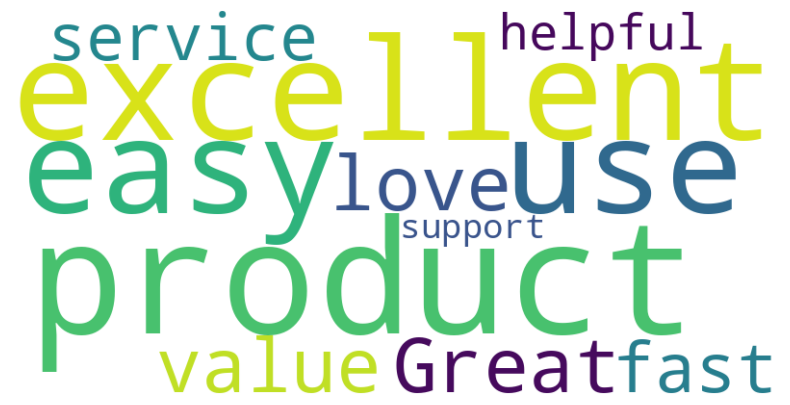

In [11]:
reviews = [
    "This product is excellent and easy to use. I love it.",
    "The quality is terrible and it stopped working quickly.",
    "The product arrived today and the package is standard.",
    "Great value, fast service, and very helpful support.",
    "I am disappointed because the app is slow and confusing."
]

from textblob import TextBlob

sentiment_results = []
positive_reviews = []

for review in reviews:
    polarity = TextBlob(review).sentiment.polarity
    subjectivity = TextBlob(review).sentiment.subjectivity
    label = "Positive" if polarity > 0.1 else "Negative" if polarity < -0.1 else "Neutral"
    sentiment_results.append((review, round(polarity, 3), round(subjectivity, 3), label))
    if label == "Positive":
        positive_reviews.append(review)

for result in sentiment_results:
    print(result)

try:
    from wordcloud import WordCloud
    if positive_reviews:
        cloud = WordCloud(width=800, height=400, background_color="white").generate(" ".join(positive_reviews))
        plt.figure(figsize=(10, 5))
        plt.imshow(cloud, interpolation="bilinear")
        plt.axis("off")
        plt.show()
    else:
        print("No positive reviews to display.")
except ImportError:
    print("Install wordcloud with: pip install wordcloud")

## Q6. Text generation with a simple neural model

In [12]:
training_text = (
    "technology helps people learn new skills. artificial intelligence can answer questions. "
    "students practise coding and build useful projects. learning requires patience and practice. "
    "good projects solve real problems. people improve by testing ideas and learning from mistakes. "
    "technology changes quickly and creates new opportunities for everyone."
)

try:
    from tensorflow.keras.preprocessing.text import Tokenizer
    from tensorflow.keras.utils import to_categorical
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Embedding, LSTM, Dense

    tokenizer = Tokenizer()
    tokenizer.fit_on_texts([training_text])
    sequences = tokenizer.texts_to_sequences([training_text])[0]
    vocab_size = len(tokenizer.word_index) + 1

    input_sequences = []
    for i in range(1, len(sequences)):
        input_sequences.append(sequences[:i + 1])

    max_len = max(len(seq) for seq in input_sequences)
    from tensorflow.keras.preprocessing.sequence import pad_sequences
    padded = pad_sequences(input_sequences, maxlen=max_len, padding="pre")
    X_train, y_train = padded[:, :-1], to_categorical(padded[:, -1], num_classes=vocab_size)

    model = Sequential([
        Embedding(vocab_size, 16, input_length=max_len - 1),
        LSTM(32),
        Dense(vocab_size, activation="softmax")
    ])
    model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
    model.fit(X_train, y_train, epochs=100, verbose=0)

    def generate_text(seed, next_words=12):
        result = seed.lower()
        for _ in range(next_words):
            seq = tokenizer.texts_to_sequences([result])[0]
            seq = pad_sequences([seq], maxlen=max_len - 1, padding="pre")
            prediction = model.predict(seq, verbose=0)[0]
            next_id = int(np.argmax(prediction))
            next_word = tokenizer.index_word.get(next_id, "")
            if not next_word:
                break
            result += " " + next_word
        return result

    print(generate_text("technology", 12))
    print(generate_text("students", 12))
    print(generate_text("learning", 12))
except ImportError:
    print("TensorFlow is not installed. Install it with: pip install tensorflow")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


technology helps helps helps helps learn learn intelligence intelligence questions questions students coding
students helps helps helps helps learn learn intelligence intelligence questions questions students coding
learning helps helps helps helps learn learn intelligence questions questions questions students coding
